# What are the VaDeSC clusters on SUPPORT, clinically?

VaDeSC on SUPPORT with only the variables known at study entry (no post-baseline variables, see notebook 01), K = 4 as in the paper's config. The clusters are described in clinical units (raw values, not standardised) on the **test set** (1,821 patients).

1. Cluster sizes and survival
2. Clinical profile of each cluster
3. Are the clusters just the diagnosis groups?
4. Which features define the clusters (a small decision tree)
5. Are the clusters stable across seeds?

Outcomes (death, hospital death, survival time) are only used to describe the clusters, never as input.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from sklearn.metrics import adjusted_rand_score
from sklearn.tree import DecisionTreeClassifier, export_text

from src.data import load_support, load_support_raw
from src.vadesc import evaluate_vadesc, train_vadesc

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 300
CFG = dict(K=4, d_lat=16, weibull_k=2.0)

d = load_support(drop_post_baseline=True)
raw = load_support_raw()
te = raw.iloc[d.idx["te"]].reset_index(drop=True)  # raw values of the test patients
assert np.allclose(te["d.time"].to_numpy(), d.t_te)

In [2]:
runs = {}
for s in SEEDS:
    m, cl, z = evaluate_vadesc(train_vadesc(d, epochs=EPOCHS, seed=s, **CFG), d)
    runs[s] = (m, cl, z)
    print(f"seed {s}: C-index {m['C-index']:.3f} | cluster sizes {np.bincount(cl, minlength=4).tolist()}", flush=True)

# main model: seed 0; clusters renumbered from highest to lowest 1-year mortality
_, cl, z0 = runs[0]
year_mort = pd.Series(((te["d.time"] <= 365) & (te["death"] == 1)).to_numpy()).groupby(cl).mean()
order = year_mort.sort_values(ascending=False).index
te["cluster"] = pd.Series(cl).map({c: f"C{i + 1}" for i, c in enumerate(order)})

seed 0: C-index 0.654 | cluster sizes [1226, 425, 80, 90]


seed 1: C-index 0.687 | cluster sizes [1203, 82, 103, 433]


seed 2: C-index 0.668 | cluster sizes [365, 61, 33, 1362]


seed 3: C-index 0.649 | cluster sizes [325, 1088, 74, 334]


seed 4: C-index 0.650 | cluster sizes [110, 406, 132, 1173]


In [3]:
# test-set clusters with the variables used below, for the poster figures (notebook 12)
keep = ["cluster", "d.time", "death", "hospdead", "age", "sex", "num.co", "scoma", "avtisst", "adlsc", "meanbp", "hrt",
        "resp", "temp", "pafi", "alb", "bili", "crea", "bun", "sod", "wblc", "diabetes", "dementia", "ca", "dzclass", "dzgroup"]
te[keep].to_csv("../results/poster/support_clusters.csv", index=False)

## 1. Cluster sizes and survival

Clusters are numbered from highest (C1) to lowest 1-year mortality.

In [4]:
def summary(g):
    return pd.Series({
        "patients": len(g),
        "share": len(g) / len(te),
        "died in hospital": g["hospdead"].mean(),
        "died within 1 year": ((g["d.time"] <= 365) & (g["death"] == 1)).mean(),
        "died during follow-up": g["death"].mean(),
        "median survival (days)": KaplanMeierFitter().fit(g["d.time"], g["death"]).median_survival_time_,
    })

surv = pd.DataFrame({c: summary(g) for c, g in te.groupby("cluster")}).T
surv.loc["all"] = summary(te)
surv.round(2)

,patients,share,died in hospital,died within 1 year,died during follow-up,median survival (days)
C1,425.0,0.23,0.61,0.80,0.87,19.0
C2,90.0,0.05,0.12,0.61,0.71,150.0
C3,80.0,0.04,0.25,0.60,0.68,150.0
C4,1226.0,0.67,0.16,0.46,0.62,440.0
all,1821.0,1.00,0.26,0.55,0.68,228.0


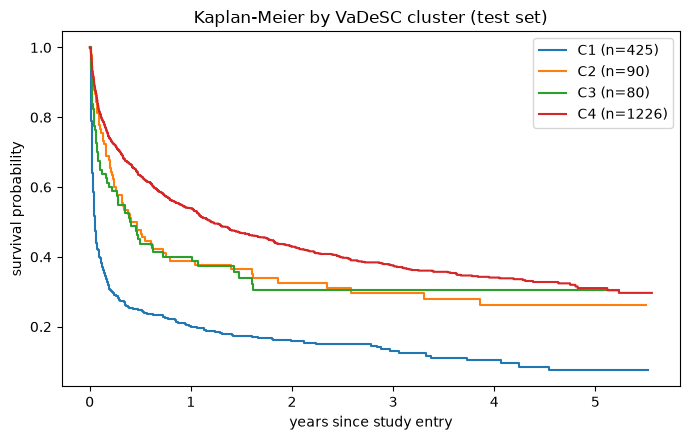

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, g in te.groupby("cluster"):
    KaplanMeierFitter(label=f"{c} (n={len(g)})").fit(g["d.time"] / 365, g["death"]).plot_survival_function(ax=ax, ci_show=False)
ax.set(xlabel="years since study entry", ylabel="survival probability", title="Kaplan-Meier by VaDeSC cluster (test set)")
plt.tight_layout(); plt.show()

## 2. Clinical profile

Medians for continuous variables (missing values ignored), percentages for binary and categorical ones.

- `scoma`: SUPPORT coma score (0 = awake, higher = deeper coma)
- `avtisst`: average TISS score, a measure of how intensive the ICU care is
- `num.co`: number of comorbidities; `adlsc`: activities of daily living (higher = more dependent)
- `meanbp` (mean blood pressure), `hrt` (heart rate), `resp` (respiratory rate), `temp`, `pafi` (PaO2/FiO2, lower = worse lung function), `alb` (albumin), `bili` (bilirubin), `crea` (creatinine), `bun` (urea), `sod` (sodium), `wblc` (white blood cells)

In [6]:
cont = ["age", "num.co", "scoma", "avtisst", "adlsc", "meanbp", "hrt", "resp", "temp",
        "pafi", "alb", "bili", "crea", "bun", "sod", "wblc"]
prof = te.groupby("cluster")[cont].median()
prof.loc["all"] = te[cont].median()

binary = pd.DataFrame({
    "female": te["sex"] == "female",
    "diabetes": te["diabetes"] == 1,
    "dementia": te["dementia"] == 1,
    "metastatic cancer": te["ca"] == "metastatic",
    "any cancer": te["ca"] != "no",
})
pct = binary.groupby(te["cluster"]).mean()
pct.loc["all"] = binary.mean()
pd.concat([prof.round(1), (100 * pct).round(0).add_suffix(" (%)")], axis=1).T

cluster,C1,C2,C3,C4,all
age,66.6,64.6,64.4,63.7,64.3
num.co,1.0,2.0,2.0,2.0,2.0
scoma,37.0,0.0,0.0,0.0,0.0
avtisst,33.0,14.0,15.7,16.6,19.7
adlsc,3.0,4.0,1.0,1.0,1.2
meanbp,69.0,75.0,77.5,80.0,77.0
hrt,110.0,80.0,105.0,94.0,98.0
resp,24.0,24.0,23.0,24.0,24.0
temp,37.1,36.3,37.4,36.7,36.8
pafi,197.5,280.0,211.5,232.9,225.7


In [7]:
# disease class and disease group (% of each cluster)
for col in ["dzclass", "dzgroup"]:
    tab = pd.crosstab(te["cluster"], te[col], normalize="index") * 100
    display(tab.round(0))

dzclass,ARF/MOSF,COPD/CHF/Cirrhosis,Cancer,Coma
cluster,,,,
C1,68.0,8.0,4.0,20.0
C2,31.0,48.0,21.0,0.0
C3,44.0,19.0,30.0,8.0
C4,42.0,37.0,19.0,2.0


dzgroup,ARF/MOSF w/Sepsis,CHF,COPD,Cirrhosis,Colon Cancer,Coma,Lung Cancer,MOSF w/Malig
cluster,,,,,,,,
C1,54.0,3.0,3.0,2.0,1.0,20.0,3.0,13.0
C2,22.0,21.0,20.0,7.0,4.0,0.0,17.0,9.0
C3,38.0,8.0,9.0,2.0,10.0,8.0,20.0,6.0
C4,36.0,18.0,13.0,7.0,6.0,2.0,12.0,6.0


## 3. Are the clusters just the diagnosis groups?

If VaDeSC only rediscovered the diagnosis, the clusters would line up with `dzclass` (4 classes, like K = 4). ARI = 1 means identical groupings, 0 means unrelated. We also check how much the diagnosis alone separates survival compared with the clusters (log-rank chi2, higher = more separated survival curves).

In [8]:
from src.metrics import logrank_chi2

print(f"ARI(clusters, dzclass) = {adjusted_rand_score(te['cluster'], te['dzclass']):.2f}")
print(f"ARI(clusters, dzgroup) = {adjusted_rand_score(te['cluster'], te['dzgroup']):.2f}")
codes = lambda s: pd.factorize(s)[0]
print(f"log-rank chi2: VaDeSC clusters {logrank_chi2(d, codes(te['cluster'])):.0f} "
      f"| dzclass {logrank_chi2(d, codes(te['dzclass'])):.0f}")

ARI(clusters, dzclass) = 0.04
ARI(clusters, dzgroup) = 0.01
log-rank chi2: VaDeSC clusters 279 | dzclass 189


## 4. Which features define the clusters?

A depth-3 decision tree predicting the cluster from the raw features (missing values filled with the median). If a shallow tree reproduces the clusters well, the clusters can be described with a few simple clinical rules.

In [9]:
feats = cont + ["sex", "diabetes", "dementia", "ca", "dzclass", "dzgroup", "race"]
Xtree = pd.get_dummies(te[feats], drop_first=False, dtype=float)
Xtree = Xtree.fillna(Xtree.median())
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(Xtree, te["cluster"])
print(f"tree accuracy (on the same patients): {tree.score(Xtree, te['cluster']):.2f}")
print(export_text(tree, feature_names=list(Xtree.columns), decimals=1))
imp = pd.Series(tree.feature_importances_, index=Xtree.columns)
imp[imp > 0].sort_values(ascending=False).round(2)

tree accuracy (on the same patients): 0.79
|--- scoma <= 39.0
|   |--- adlsc <= 3.8
|   |   |--- crea <= 2.5
|   |   |   |--- class: C4
|   |   |--- crea >  2.5
|   |   |   |--- class: C4
|   |--- adlsc >  3.8
|   |   |--- avtisst <= 22.5
|   |   |   |--- class: C4
|   |   |--- avtisst >  22.5
|   |   |   |--- class: C1
|--- scoma >  39.0
|   |--- scoma <= 75.0
|   |   |--- adlsc <= 3.0
|   |   |   |--- class: C1
|   |   |--- adlsc >  3.0
|   |   |   |--- class: C1
|   |--- scoma >  75.0
|   |   |--- bun <= 26.5
|   |   |   |--- class: C1
|   |   |--- bun >  26.5
|   |   |   |--- class: C1



scoma      0.48
adlsc      0.33
crea       0.12
avtisst    0.07
bun        0.00
dtype: float64

## 5. Stability across seeds

Each seed retrains VaDeSC from scratch. ARI between the test-set clusterings of two seeds shows how reproducible the grouping is (cluster numbers don't need to match; ARI ignores labels). We also check whether a dementia cluster appears in every run.

In [10]:
pairs = [(a, b, adjusted_rand_score(runs[a][1], runs[b][1])) for i, a in enumerate(SEEDS) for b in SEEDS[i + 1:]]
ari = pd.DataFrame(pairs, columns=["seed a", "seed b", "ARI"])
print(f"ARI between seeds: mean {ari.ARI.mean():.2f}, min {ari.ARI.min():.2f}, max {ari.ARI.max():.2f}")
print(f"C-index over seeds: {np.mean([runs[s][0]['C-index'] for s in SEEDS]):.3f} "
      f"± {np.std([runs[s][0]['C-index'] for s in SEEDS], ddof=1):.3f}")

rows = []
for s in SEEDS:
    c = runs[s][1]
    for k in np.unique(c):
        g = te[c == k]
        rows.append({"seed": s, "cluster": k, "size": len(g), "dementia (%)": 100 * (g["dementia"] == 1).mean(),
                     "metastatic cancer (%)": 100 * (g["ca"] == "metastatic").mean(),
                     "coma class (%)": 100 * (g["dzclass"] == "Coma").mean(),
                     "1-year mortality (%)": 100 * ((g["d.time"] <= 365) & (g["death"] == 1)).mean(),
                     "median age": g["age"].median()})
pd.DataFrame(rows).round(0).set_index(["seed", "cluster"])

ARI between seeds: mean 0.52, min 0.33, max 0.73
C-index over seeds: 0.662 ± 0.016


size  dementia (%)  metastatic cancer (%)  coma class (%)  \
seed cluster                                                              
0    0        1226           1.0                   23.0             2.0   
     1         425           9.0                   10.0            20.0   
     2          80          10.0                   34.0             8.0   
     3          90           2.0                   30.0             0.0   
1    0        1203           0.0                   23.0             2.0   
     1          82           1.0                   32.0             0.0   
     2         103          10.0                   23.0             7.0   
     3         433          12.0                   10.0            18.0   
2    0         365           0.0                   15.0            20.0   
     1          61         100.0                    3.0            10.0   
     2          33           0.0                   21.0            12.0   
     3        1362           0.0                   23.0             2.0   
3    0         325           0.0                   58.0             1.0   
     1        1088           0.0                   14.0             2.0   
     2          74          82.0                    4.0            11.0   
     3         334           0.0                   10.0            22.0   
4    0         110           0.0                   98.0             0.0   
     1         406          11.0                    9.0            19.0   
     2         132          12.0                   26.0             5.0   
     3        1173           0.0                   17.0             2.0   

              1-year mortality (%)  median age  
seed cluster                                    
0    0                        46.0        64.0  
     1                        80.0        67.0  
     2                        60.0        64.0  
     3                        61.0        65.0  
1    0                        47.0        64.0  
     1                        67.0        64.0  
     2                        55.0        65.0  
     3                        75.0        67.0  
2    0                        82.0        65.0  
     1                        57.0        77.0  
     2                        64.0        65.0  
     3                        48.0        64.0  
3    0                        58.0        66.0  
     1                        45.0        63.0  
     2                        58.0        75.0  
     3                        84.0        65.0  
4    0                        75.0        64.0  
     1                        76.0        67.0  
     2                        61.0        66.0  
     3                        46.0        64.0

## 6. Are the clusters more than a risk score?

The clusters look mostly ordered by how sick patients are. A simpler way to get risk groups: fit a Cox model on the same training data and split the test patients into 4 equal groups by predicted risk (quartiles). If these risk groups separate survival as well as the clusters, the clusters add little beyond a risk score. We also check how much the two groupings agree, and whether the C1 patients are simply the highest-risk patients.

In [11]:
from sksurv.linear_model import CoxPHSurvivalAnalysis

cox = CoxPHSurvivalAnalysis(alpha=0.1, ties="efron").fit(d.X_tr, d.y_tr)  # same settings as run_cox
risk = cox.predict(d.X_te)
quart = pd.qcut(risk, 4, labels=["Q4 (highest risk)", "Q3", "Q2", "Q1 (lowest risk)"][::-1]).astype(str)
te["Cox risk quartile"] = quart

def groups_summary(col):
    g = te.groupby(col)
    return pd.DataFrame({"patients": g.size(),
                         "died within 1 year (%)": 100 * g.apply(lambda x: ((x["d.time"] <= 365) & (x["death"] == 1)).mean(), include_groups=False),
                         "median survival (days)": g.apply(lambda x: KaplanMeierFitter().fit(x["d.time"], x["death"]).median_survival_time_, include_groups=False)}).round(0)

print(f"log-rank chi2 (higher = survival curves more separated): VaDeSC clusters {logrank_chi2(d, codes(te['cluster'])):.0f} "
      f"| Cox risk quartiles {logrank_chi2(d, codes(te['Cox risk quartile'])):.0f} | disease class {logrank_chi2(d, codes(te['dzclass'])):.0f}")
print(f"ARI(clusters, Cox risk quartiles) = {adjusted_rand_score(te['cluster'], te['Cox risk quartile']):.2f}")
top = risk >= np.quantile(risk, 1 - (te["cluster"] == "C1").mean())  # as many highest-risk patients as C1 has
c1 = (te["cluster"] == "C1").to_numpy()
print(f"C1 patients in the top {c1.mean():.0%} of Cox risk: {top[c1].mean():.0%} (would be {c1.mean():.0%} by chance)")
display(groups_summary("Cox risk quartile"))
display(groups_summary("cluster"))
pd.crosstab(te["cluster"], te["Cox risk quartile"], margins=True)

log-rank chi2 (higher = survival curves more separated): VaDeSC clusters 279 | Cox risk quartiles 710 | disease class 189
ARI(clusters, Cox risk quartiles) = 0.07
C1 patients in the top 23% of Cox risk: 57% (would be 23% by chance)


,patients,died within 1 year (%),median survival (days)
Cox risk quartile,,,
Q1 (lowest risk),456,24.0,inf
Q2,455,43.0,584.0
Q3,455,67.0,121.0
Q4 (highest risk),455,87.0,19.0


,patients,died within 1 year (%),median survival (days)
cluster,,,
C1,425,80.0,19.0
C2,90,61.0,150.0
C3,80,60.0,150.0
C4,1226,46.0,440.0


Cox risk quartile,Q1 (lowest risk),Q2,Q3,Q4 (highest risk),All
cluster,,,,,
C1,11,62,100,252,425
C2,16,26,30,18,90
C3,25,11,32,12,80
C4,404,356,293,173,1226
All,456,455,455,455,1821


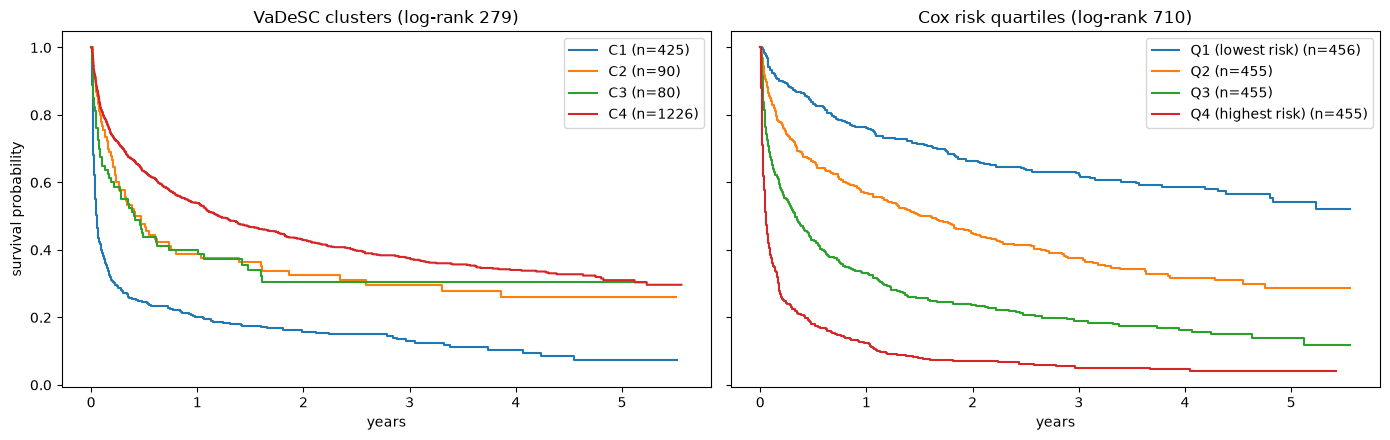

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, col, title in [(ax[0], "cluster", "VaDeSC clusters"), (ax[1], "Cox risk quartile", "Cox risk quartiles")]:
    for g, x in te.groupby(col):
        KaplanMeierFitter(label=f"{g} (n={len(x)})").fit(x["d.time"] / 365, x["death"]).plot_survival_function(ax=a, ci_show=False)
    a.set(title=f"{title} (log-rank {logrank_chi2(d, codes(te[col])):.0f})", xlabel="years", ylabel="survival probability")
plt.tight_layout(); plt.show()

## 7. What does the latent space look like?

The same test patients in 2D: PCA of the (standardised) input features, and PCA / t-SNE of VaDeSC's 16-dimensional latent embedding (the encoder mean). Coloured by cluster and by outcome. Explained variance is shown on the PCA axes.

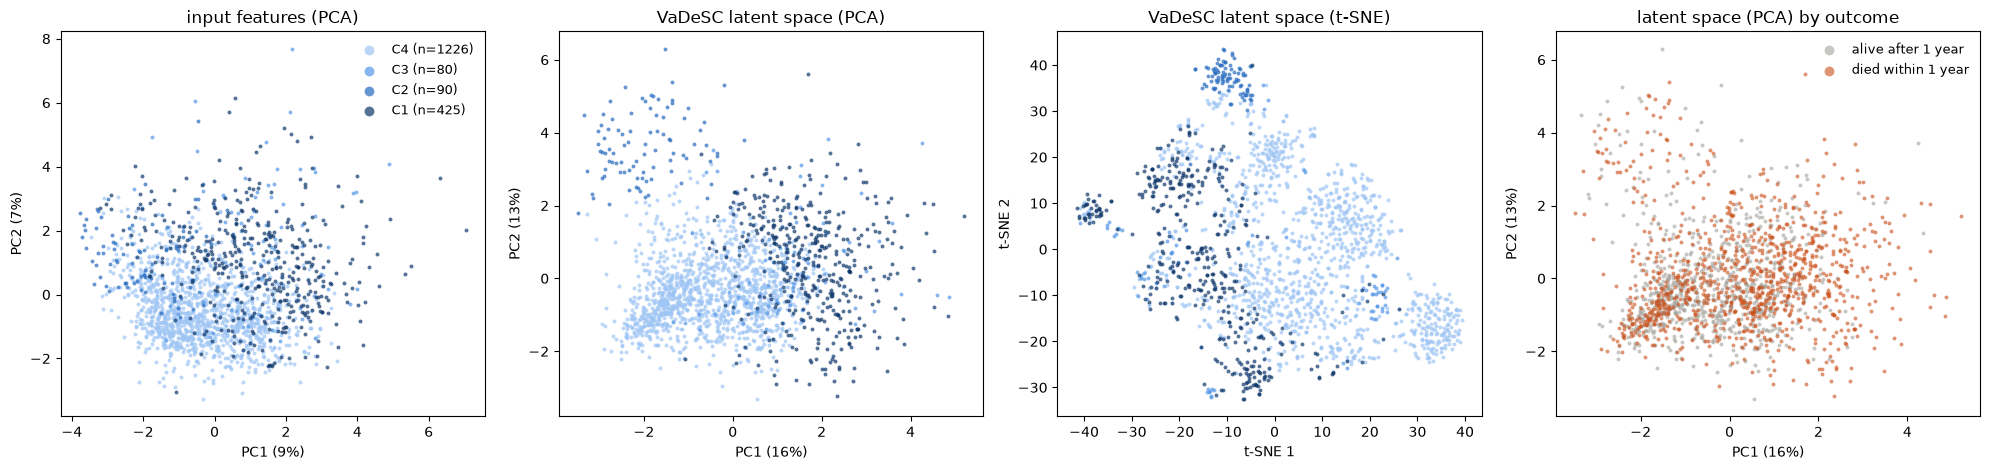

In [13]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

z0 = np.asarray(z0)
pca_x, pca_z = PCA(2).fit(d.X_te), PCA(2).fit(z0)
px, pz = pca_x.transform(d.X_te), pca_z.transform(z0)
tz = TSNE(2, perplexity=40, init="pca", random_state=0).fit_transform(z0)
died_1y = ((te["d.time"] <= 365) & (te["death"] == 1)).to_numpy()

lat = pd.DataFrame({"cluster": te["cluster"], "died within 1 year": died_1y, "scoma": te["scoma"],
                    "input PC1": px[:, 0], "input PC2": px[:, 1], "latent PC1": pz[:, 0], "latent PC2": pz[:, 1],
                    "latent tSNE1": tz[:, 0], "latent tSNE2": tz[:, 1]})
lat.attrs = {}
lat.to_csv("../results/poster/support_latent.csv", index=False)
ev = lambda p: [f"PC{i + 1} ({v:.0%})" for i, v in enumerate(p.explained_variance_ratio_)]

cols = dict(zip(sorted(te["cluster"].unique()), ["#0d366b", "#256abf", "#5598e7", "#9ec5f4"]))
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
for a, (x, y, title, labs) in zip(ax[:3], [(px, None, "input features (PCA)", ev(pca_x)),
                                           (pz, None, "VaDeSC latent space (PCA)", ev(pca_z)),
                                           (tz, None, "VaDeSC latent space (t-SNE)", ["t-SNE 1", "t-SNE 2"])]):
    for c in sorted(cols, reverse=True):  # big cluster drawn first
        m = (te["cluster"] == c).to_numpy()
        a.scatter(x[m, 0], x[m, 1], s=8, color=cols[c], alpha=0.7, label=f"{c} (n={m.sum()})", linewidths=0)
    a.set(title=title, xlabel=labs[0], ylabel=labs[1])
ax[0].legend(markerscale=2.5, frameon=False, fontsize=9)
for flag, col, lab in [(False, "#a3a29b", "alive after 1 year"), (True, "#c94e17", "died within 1 year")]:
    ax[3].scatter(pz[died_1y == flag, 0], pz[died_1y == flag, 1], s=8, color=col, alpha=0.6, label=lab, linewidths=0)
ax[3].set(title="latent space (PCA) by outcome", xlabel=ev(pca_z)[0], ylabel=ev(pca_z)[1])
ax[3].legend(markerscale=2.5, frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## Notes

Seed 0 (the model described above), clusters numbered by 1-year mortality:

- **C1, critically ill (23%)**: deep coma more often (median coma score 37, 20% in the coma class), intensive ICU care (TISS 33), low blood pressure, fast heart rate, low albumin, mostly acute respiratory failure / multi-organ failure with sepsis. 61% died in hospital, median survival 19 days.
- **C4, the large lower-risk group (67%)**: awake, less intensive care, mixed diagnoses. Median survival 440 days.
- **C2 (5%)**: more dependent in daily activities (ADL 4), more chronic disease (COPD / heart failure / cirrhosis 48%), lower care intensity. Median survival 150 days.
- **C3 (4%)**: signs of kidney dysfunction and inflammation (creatinine 2.1, urea 57.5, white cells 16.2), more cancer (50%). Median survival 150 days.

What this means:
- The clusters are **not** the diagnosis groups (ARI with `dzclass` 0.04), and they separate survival better than the diagnosis (log-rank 279 vs 189). They are mainly ordered by **how sick the patient is at entry**: a 3-level tree on coma score, ADL and creatinine reproduces 79% of the assignments (always guessing the largest cluster, C4, would already give 67%), but it only ever predicts C1 or C4, so the two small clusters are not captured by simple rules.
- **Stability is moderate** (ARI 0.52 between seeds). Two clusters come back in every seed: a large lower-risk group (about 1,100-1,350 patients, ~46% 1-year mortality) and a critically ill / coma group (about 330-430 patients, 75-84% 1-year mortality). The small clusters change between seeds: a dementia cluster (82-100% dementia, median age 75-77) in seeds 2 and 3 only, a metastatic-cancer cluster in seed 4. So only the two large groups should be interpreted clinically.
- C-index 0.662 ± 0.016 over 5 seeds, as in notebooks 01 and 10 for baseline-only SUPPORT.
- **Compared with a simple risk score (section 6)**: 4 equal groups from Cox's predicted risk separate survival much better than the VaDeSC clusters (log-rank 710 vs 279; 1-year mortality 24% to 87% across quartiles vs 46% to 80% across clusters). The two groupings agree little (ARI 0.07): C1 is enriched in the highest-risk quartile (57% of C1 vs 23% by chance), but C4 contains patients from every quartile. So on SUPPORT the clusters are neither clearly distinct clinical subgroups nor a better risk stratification than Cox. (Caveat: the quartiles have equal sizes, while the clusters are unbalanced, which also lowers the log-rank statistic for the clusters.)
